In [ ]:
# Import libraries and prepare the dataset

import os
import zipfile
import tensorflow as tf
import matplotlib.pyplot as plt

from google.colab import drive
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report

drive.mount("/content/drive")

ZIP_PATH = "/content/drive/MyDrive/leaf_dataset/dataset.zip"
DATA_DIR = "/content/leaf_dataset"

IMG_SIZE = (64, 48)
BATCH_SIZE = 64
EPOCHS = 30
SEED = 42

if not os.path.exists(DATA_DIR):
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall(DATA_DIR)

dataset_dir = DATA_DIR

if len(os.listdir(dataset_dir)) == 1:
    folder = os.path.join(dataset_dir, os.listdir(dataset_dir)[0])
    if os.path.isdir(folder):
        dataset_dir = folder

print("Dataset:", dataset_dir)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset: /content/leaf_dataset/dataset


In [ ]:
# Load and split the dataset into training, validation and test sets

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    validation_split=0.30,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

temp_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    validation_split=0.30,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

class_names = train_ds.class_names

n = tf.data.experimental.cardinality(temp_ds)
half = n // 2

val_ds = temp_ds.take(half)
test_ds = temp_ds.skip(half)

print("Classes:", class_names)
print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

Found 4948 files belonging to 2 classes.
Using 3464 files for training.
Found 4948 files belonging to 2 classes.
Using 1484 files for validation.
Classes: ['aam_pata', 'kathal_pata']
Train batches: 55
Validation batches: 12
Test batches: 12


In [ ]:
# Optimize the input pipeline for faster training

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().shuffle(1000).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)
test_ds = test_ds.cache().prefetch(AUTOTUNE)

In [ ]:
# Define lightweight image augmentation

augmentation = keras.Sequential([
    layers.RandomRotation(0.08),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomFlip("horizontal")
])

def augment(x, y):
    return augmentation(x, training=True), y

train_aug = train_ds.map(
    augment,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

In [ ]:
# Define the CNN with three convolutional layers

model = keras.Sequential([
    layers.Input(shape=(*IMG_SIZE, 3)),

    layers.Rescaling(1./255),

    layers.Conv2D(
        8, (3, 3),
        padding="same",
        strides=1,
        activation="relu"
    ),

    layers.Conv2D(
        8, (3, 3),
        padding="same",
        strides=1,
        activation="relu"
    ),

    layers.Conv2D(
        8, (3, 3),
        padding="same",
        strides=1,
        activation="relu"
    ),

    layers.Flatten(),

    layers.Dense(1, activation="sigmoid")
])

In [ ]:
# Compile the model and display its summary

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0003),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_3 (Rescaling)         │ (None, 64, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 64, 48, 8)      │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 64, 48, 8)      │           584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 64, 48, 8)      │           584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 24576)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │        24,577 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,969 (101.44 KB)

 Trainable params: 25,969 (101.44 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train the CNN with early stopping

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4
)
]

history = model.fit(
    train_aug,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 9s 96ms/step - accuracy: 0.5242 - loss: 0.6921 - val_accuracy: 0.5326 - val_loss: 0.6905 - learning_rate: 3.0000e-04
Epoch 2/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.5759 - loss: 0.6741 - val_accuracy: 0.5977 - val_loss: 0.6734 - learning_rate: 3.0000e-04
Epoch 3/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.6233 - loss: 0.6477 - val_accuracy: 0.6302 - val_loss: 0.6396 - learning_rate: 3.0000e-04
Epoch 4/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.6400 - loss: 0.6270 - val_accuracy: 0.6602 - val_loss: 0.6103 - learning_rate: 3.0000e-04
Epoch 5/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.6628 - loss: 0.6019 - val_accuracy: 0.6797 - val_loss: 0.5957 - learning_rate: 3.0000e-04
Epoch 6/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 4s 55ms/step - accuracy: 0.6827 - loss: 0.5892 - val_accuracy: 0.6562 - val_loss: 0.5906 - learning_rate: 3.0000e-04
Epoch 7/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.6836 

In [ ]:
# Evaluate the final model on the unseen test dataset

test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Test Loss: 0.4828
Test Accuracy: 0.7584


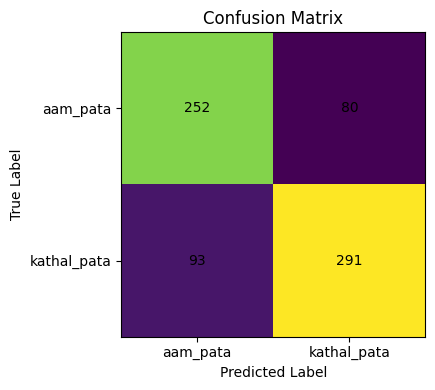

              precision    recall  f1-score   support

    aam_pata       0.73      0.76      0.74       332
 kathal_pata       0.78      0.76      0.77       384

    accuracy                           0.76       716
   macro avg       0.76      0.76      0.76       716
weighted avg       0.76      0.76      0.76       716



In [ ]:
# Generate and plot the confusion matrix

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)
    y_true.extend(labels.numpy().ravel())
    y_pred.extend((predictions >= 0.5).astype(int).ravel())

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks([0, 1], class_names)
plt.yticks([0, 1], class_names)

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

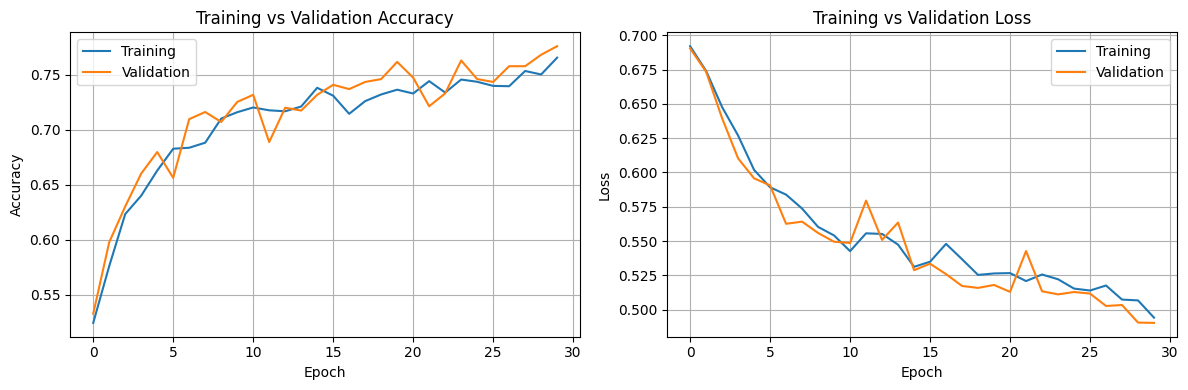

In [ ]:
# Plot training and validation accuracy and loss

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)

plt.plot(
    history.history["accuracy"],
    label="Training"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)

plt.plot(
    history.history["loss"],
    label="Training"
)

plt.plot(
    history.history["val_loss"],
    label="Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [ ]:
# Print final training, validation and test performance

train_loss, train_acc = model.evaluate(train_ds, verbose=0)
val_loss, val_acc = model.evaluate(val_ds, verbose=0)
test_loss, test_acc = model.evaluate(test_ds, verbose=0)

print(f"Train Accuracy: {train_acc:.4f}")
print(f"Train Loss: {train_loss:.4f}")
print(f"Validation Accuracy: {val_acc:.4f}")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Loss: {test_loss:.4f}")

Train Accuracy: 0.7812
Train Loss: 0.4716
Validation Accuracy: 0.7760
Validation Loss: 0.4903
Test Accuracy: 0.7584
Test Loss: 0.4828
